

1	Dataset load aur inspect	

2	EDA aur target distribution	

3	Train-test split	

4	Feature engineering aur interaction features	

5	Missing values aur categorical encoding	
	
6	Correlation heatmap aur multicollinearity analysis	

7	OLS, Ridge aur Lasso models	

8	GridSearchCV se Ridge/Lasso 

9	RMSE, MAE, R² comparison	

10	Predicted vs actual aur residual plots	

11	Conclusion, README aur GitHub submission


# Task 2: Real Estate Housing Price Prediction

## 1. Project Overview

The objective of this project is to predict median house values
using the California Housing dataset.

We will build and compare three regression models:
- Ordinary Least Squares (Linear Regression)
- Ridge Regression (L2 regularization)
- Lasso Regression (L1 regularization)

## Project Objectives

1. Load and explore the housing dataset.
2. Identify and handle missing values.
3. Perform exploratory data analysis (EDA).
4. Analyze correlations and multicollinearity.
5. Perform feature engineering and preprocessing.
6. Train and tune regression models using GridSearchCV.
7. Evaluate models using RMSE, MAE, and R².
8. Analyze residual errors and compare model performance.

## Dataset

The project uses the California Housing dataset from a public
GitHub repository. The dataset will be loaded directly using
its URL, so a separate local CSV file is not required.

## Expected Outcome

A documented Jupyter Notebook containing the data analysis,
preprocessing steps, trained regression models, evaluation
metrics, visualizations, and final conclusions.

## 2. Import Required Libraries

Before loading the dataset, we import the Python libraries
needed for data analysis, visualization, and machine learning.

- Pandas: Load and manipulate tabular data.
- NumPy: Perform numerical operations.
- Matplotlib: Create plots and charts.
- Seaborn: Create statistical visualizations.

We will import additional Scikit-learn tools in the relevant
sections when we begin preprocessing and model training.

In [1]:
# Import libraries for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## 3. Load the California Housing Dataset

We will load the dataset directly from its public CSV URL
using `pandas.read_csv()`.

The URL points to the raw CSV file, allowing Pandas to read
the dataset directly into a DataFrame.

We store the dataset in a variable named `df`. This DataFrame
will be used throughout the project for data inspection,
cleaning, visualization, and model preparation.

At this stage, we are only loading the data. We have not yet
handled missing values or trained any regression models.

In [2]:
# URL of the California Housing dataset
url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"

# Load the CSV data into a Pandas DataFrame
df = pd.read_csv(url)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## 4. Initial Dataset Inspection

Before performing analysis, we need to understand the
structure and quality of the dataset.

We will:
- Check the number of rows and columns.
- Preview the first five records.
- Inspect column names, data types, and non-null counts.
- Count missing values in each column.

This step helps us identify numerical and categorical
features and decide what preprocessing is required next.

In [3]:
# Check the number of rows and columns
print("Dataset shape:", df.shape)

# Display the first five rows
display(df.head())

# Inspect column names, data types, and non-null values
df.info()

# Count missing values in each column
print("\nMissing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

Dataset shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing values per column:


,Missing Values
longitude,0
latitude,0
housing_median_age,0
total_rooms,0
total_bedrooms,207
population,0
households,0
median_income,0
median_house_value,0
ocean_proximity,0


## 5. Exploratory Data Analysis (EDA)

Exploratory Data Analysis helps us understand the dataset before
preprocessing and model training.

In this section, we will:
- Examine summary statistics of numerical features.
- Check the distribution of the `ocean_proximity` categories.
- Visualize the distribution of median house values.

These checks help us understand the data, identify unusual
patterns, and plan the next preprocessing steps.

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


Ocean Proximity Category Counts:


,Count
ocean_proximity,
<1H OCEAN,9136
INLAND,6551
NEAR OCEAN,2658
NEAR BAY,2290
ISLAND,5


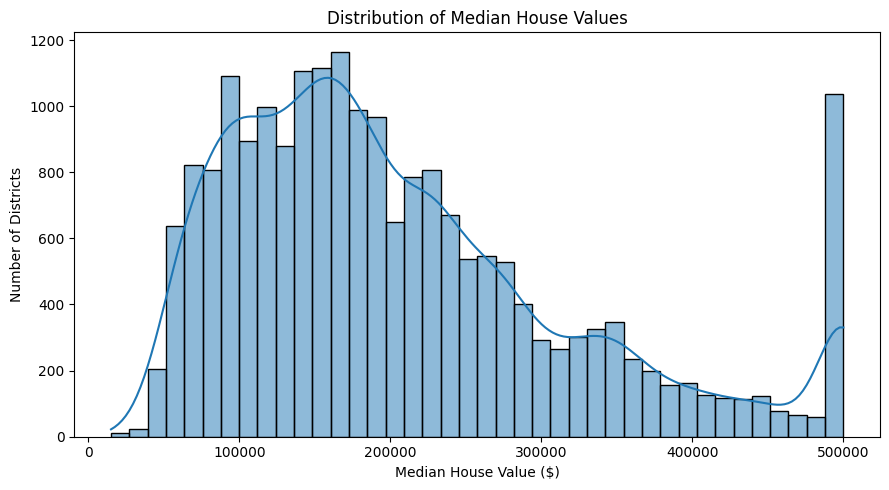

In [4]:
# Summary statistics for numerical columns
display(df.describe().T)

# Count observations in each ocean proximity category
print("Ocean Proximity Category Counts:")
display(df["ocean_proximity"].value_counts().to_frame(name="Count"))

# Visualize the distribution of median house values
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="median_house_value",
    bins=40,
    kde=True
)

plt.title("Distribution of Median House Values")
plt.xlabel("Median House Value ($)")
plt.ylabel("Number of Districts")
plt.tight_layout()
plt.show()

## 6. Separate Features and Split the Dataset

We separate the input features (X) from the target variable (y).

- X contains the information used to predict house values.
- y contains the actual median house values.

We split the dataset into 80% training data and 20% testing data.
The training data will be used to fit the models, while the
testing data will evaluate their performance on unseen data.

We split the data before fitting preprocessing steps to avoid
data leakage from the test set.

In [5]:
# Import the train-test split function
from sklearn.model_selection import train_test_split

# Separate input features and target
X = df.drop(columns=["median_house_value"])
y = df["median_house_value"]

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

# Display the shapes of the resulting datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (16512, 9)
Testing features: (4128, 9)
Training target: (16512,)
Testing target: (4128,)


## 7. Feature Engineering

Feature engineering creates new input features from existing
columns to help regression models identify useful patterns.

We will create the following features:

- `rooms_per_household`: Total rooms divided by households.
- `bedrooms_per_room`: Total bedrooms divided by total rooms.
- `population_per_household`: Population divided by households.
- `income_x_house_age`: Interaction between median income and
  housing median age.

We will apply the same transformations separately to the
training and testing features. Missing values created by
existing or derived features will be handled in preprocessing.

In [6]:
# Create new features from existing housing data
def add_housing_features(data):
    data = data.copy()

    data["rooms_per_household"] = (
        data["total_rooms"] / data["households"].replace(0, np.nan)
    )

    data["bedrooms_per_room"] = (
        data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
    )

    data["population_per_household"] = (
        data["population"] / data["households"].replace(0, np.nan)
    )

    # Interaction feature
    data["income_x_house_age"] = (
        data["median_income"] * data["housing_median_age"]
    )

    return data


# Apply identical feature engineering to both datasets
X_train = add_housing_features(X_train)
X_test = add_housing_features(X_test)

# Verify the updated datasets
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

display(X_train.head())

Training features: (16512, 13)
Testing features: (4128, 13)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,ocean_proximity,rooms_per_household,bedrooms_per_room,population_per_household,income_x_house_age
14196,-117.03,32.71,33.0,3126.0,627.0,2300.0,623.0,3.2596,NEAR OCEAN,5.017657,0.200576,3.691814,107.5668
8267,-118.16,33.77,49.0,3382.0,787.0,1314.0,756.0,3.8125,NEAR OCEAN,4.473545,0.232703,1.738095,186.8125
17445,-120.48,34.66,4.0,1897.0,331.0,915.0,336.0,4.1563,NEAR OCEAN,5.645833,0.174486,2.723214,16.6252
14265,-117.11,32.69,36.0,1421.0,367.0,1418.0,355.0,1.9425,NEAR OCEAN,4.002817,0.258269,3.994366,69.9300
2271,-119.80,36.78,43.0,2382.0,431.0,874.0,380.0,3.5542,INLAND,6.268421,0.180940,2.300000,152.8306


## 8. Data Preprocessing: Missing Values, Scaling and Encoding

The dataset contains missing values in `total_bedrooms`.
Feature engineering can also produce missing values when
a derived feature depends on a missing value.

We will build a preprocessing pipeline that:

- Imputes missing numerical values using the median.
- Scales numerical features using StandardScaler.
- Imputes missing categorical values using the most frequent value.
- Encodes `ocean_proximity` using OneHotEncoder.

The preprocessing will be fitted on training data only.
We will integrate it into the model pipelines later so that
cross-validation does not leak information between folds.

In [7]:
# Import preprocessing tools
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

# Identify numerical and categorical columns
numeric_features = X_train.select_dtypes(
    include=np.number
).columns.tolist()

categorical_features = X_train.select_dtypes(
    exclude=np.number
).columns.tolist()

print("Number of numerical features:", len(numeric_features))
print("Categorical features:", categorical_features)

# Preprocessing pipeline for numerical features
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Preprocessing pipeline for categorical features
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("num", numeric_pipeline, numeric_features),
    ("cat", categorical_pipeline, categorical_features)
])

print("\nPreprocessing pipeline configured successfully.")

Number of numerical features: 12
Categorical features: ['ocean_proximity']

Preprocessing pipeline configured successfully.


## 9. Correlation Heatmap and Multicollinearity Analysis

Correlation analysis helps us understand the relationships
between numerical features.

We will:
- Create a correlation matrix and heatmap.
- Identify features that are strongly correlated.
- Calculate the Variance Inflation Factor (VIF) to investigate
  multicollinearity.

Multicollinearity occurs when input features are strongly
related to one another. It can make regression coefficients
less stable, especially in Ordinary Least Squares regression.

For this diagnostic analysis, missing numerical values will
be imputed using medians learned from the training data only.

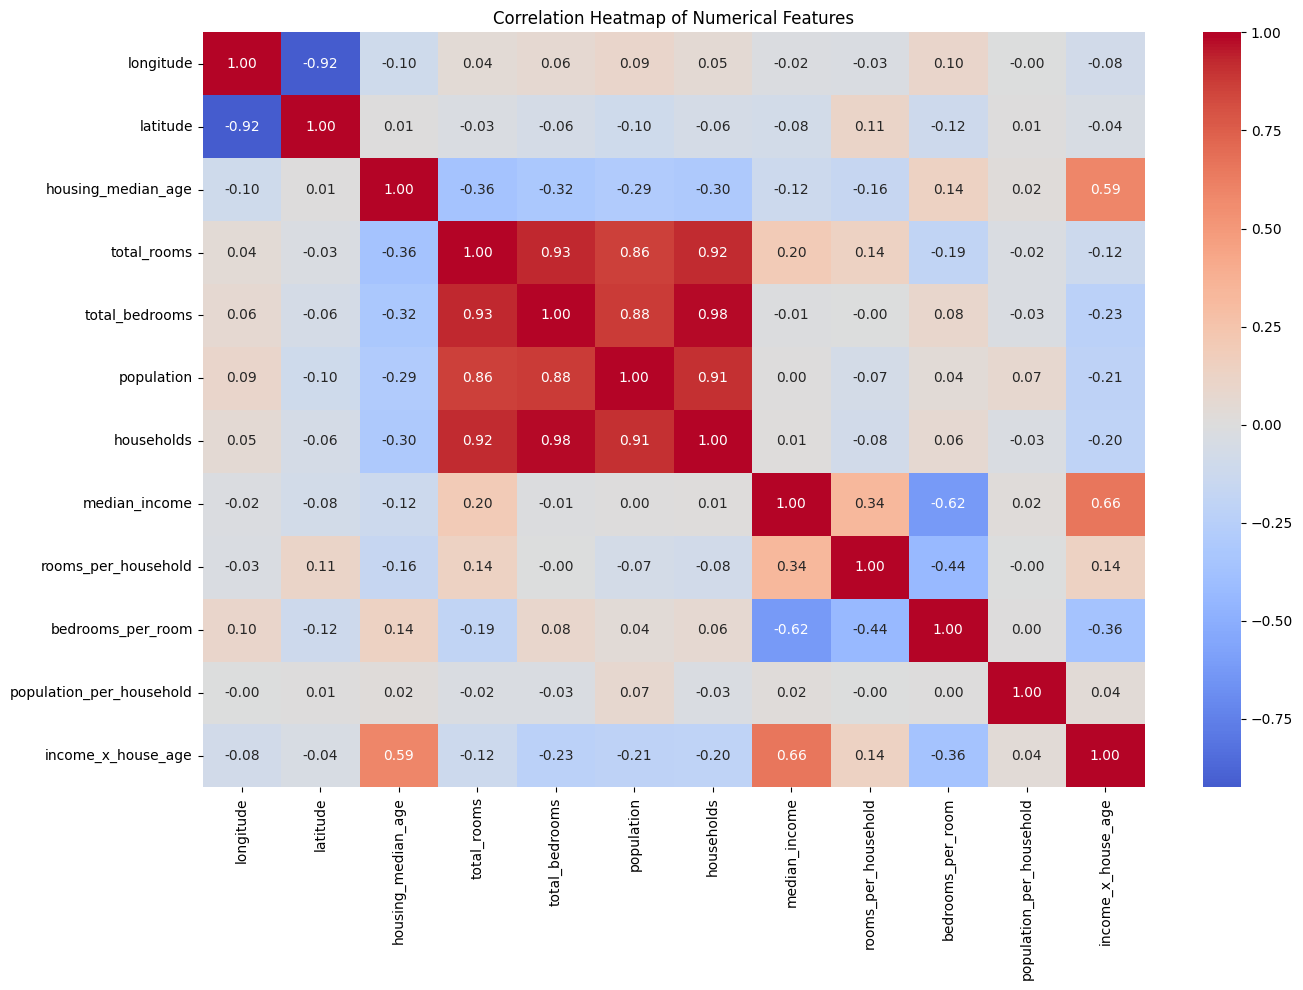

Variance Inflation Factor (VIF):


,Feature,VIF
4,total_bedrooms,50.698115
6,households,46.003874
3,total_rooms,19.549993
1,latitude,9.418306
0,longitude,9.090802
11,income_x_house_age,9.087908
7,median_income,7.589503
5,population,6.816582
2,housing_median_age,5.443811
9,bedrooms_per_room,2.807264



Features with VIF greater than 5:


,Feature,VIF
4,total_bedrooms,50.698115
6,households,46.003874
3,total_rooms,19.549993
1,latitude,9.418306
0,longitude,9.090802
11,income_x_house_age,9.087908
7,median_income,7.589503
5,population,6.816582
2,housing_median_age,5.443811


In [8]:
# Import the tools needed for multicollinearity analysis
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression

# Calculate correlations between numerical input features
correlation_matrix = X_train[numeric_features].corr()

# Plot the correlation heatmap
plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

# Impute missing values for VIF analysis using training data only
vif_imputer = SimpleImputer(strategy="median")

numeric_train_for_vif = pd.DataFrame(
    vif_imputer.fit_transform(X_train[numeric_features]),
    columns=numeric_features,
    index=X_train.index
)

# Calculate VIF for each numerical feature
vif_records = []

for feature in numeric_train_for_vif.columns:
    y_feature = numeric_train_for_vif[feature]
    X_other_features = numeric_train_for_vif.drop(columns=[feature])

    auxiliary_model = LinearRegression()
    auxiliary_model.fit(X_other_features, y_feature)

    r_squared = auxiliary_model.score(X_other_features, y_feature)

    vif = (
        np.inf
        if r_squared >= 0.999999
        else 1 / (1 - r_squared)
    )

    vif_records.append({
        "Feature": feature,
        "VIF": vif
    })

vif_df = pd.DataFrame(vif_records).sort_values(
    "VIF",
    ascending=False
)

print("Variance Inflation Factor (VIF):")
display(vif_df)

print("\nFeatures with VIF greater than 5:")
display(vif_df[vif_df["VIF"] > 5])

### 9.2 Correlation with the Target Variable

We will examine the correlation between each numerical input
feature and `median_house_value`.

This helps us understand which features have stronger positive
or negative linear relationships with house values.

We will use only the training data for this analysis.
Correlation indicates association, not causation.

,Correlation with House Value
bedrooms_per_room,-0.257419
latitude,-0.142983
longitude,-0.046349
population,-0.026032
population_per_household,-0.022030
total_bedrooms,0.047980
households,0.063714
housing_median_age,0.103706
total_rooms,0.133989
rooms_per_household,0.158485


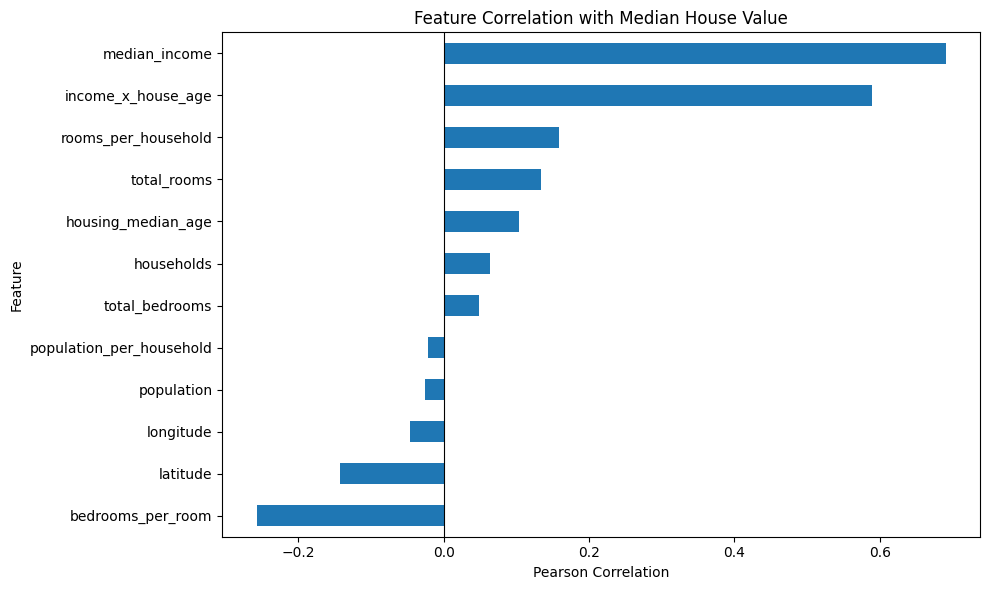

In [9]:
# Combine numerical training features with the target
target_corr_data = X_train[numeric_features].copy()
target_corr_data["median_house_value"] = y_train

# Calculate and sort correlations with the target
target_correlations = (
    target_corr_data.corr()["median_house_value"]
    .drop("median_house_value")
    .sort_values()
)

# Display correlation values
display(
    target_correlations.to_frame(
        name="Correlation with House Value"
    )
)

# Visualize correlations with the target
plt.figure(figsize=(10, 6))

target_correlations.plot(kind="barh")

plt.axvline(0, color="black", linewidth=0.8)
plt.title("Feature Correlation with Median House Value")
plt.xlabel("Pearson Correlation")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

## 10. Regression Model Training and Hyperparameter Tuning

We will train and compare three regression approaches:

- Ordinary Least Squares (OLS): A baseline linear regression model.
- Ridge Regression (L2): Adds a penalty to reduce large coefficients.
- Lasso Regression (L1): Can shrink some coefficients to zero.

We will use a preprocessing pipeline for missing-value imputation,
feature scaling, and categorical encoding.

Ridge and Lasso will be tuned using GridSearchCV with five-fold
cross-validation. The best alpha will be selected using the
negative root mean squared error scoring method.

In [10]:
# Import regression models and hyperparameter tuning tools
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline

# 1. Train the baseline OLS model
ols_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

ols_model.fit(X_train, y_train)

print("OLS model trained successfully.")

# 2. Tune Ridge Regression using GridSearchCV
ridge_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Ridge())
])

ridge_param_grid = {
    "regressor__alpha": [0.1, 1.0, 10.0, 100.0]
}

ridge_search = GridSearchCV(
    estimator=ridge_pipeline,
    param_grid=ridge_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

ridge_search.fit(X_train, y_train)

print("\nBest Ridge alpha:", ridge_search.best_params_["regressor__alpha"])
print("Best Ridge CV RMSE:", -ridge_search.best_score_)

# 3. Tune Lasso Regression using GridSearchCV
lasso_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", Lasso(max_iter=20000))
])

lasso_param_grid = {
    "regressor__alpha": [0.001, 0.01, 0.1, 1.0, 10.0]
}

lasso_search = GridSearchCV(
    estimator=lasso_pipeline,
    param_grid=lasso_param_grid,
    scoring="neg_root_mean_squared_error",
    cv=5,
    n_jobs=-1
)

lasso_search.fit(X_train, y_train)

print("\nBest Lasso alpha:", lasso_search.best_params_["regressor__alpha"])
print("Best Lasso CV RMSE:", -lasso_search.best_score_)

OLS model trained successfully.

Best Ridge alpha: 1.0
Best Ridge CV RMSE: 67720.72484368541

Best Lasso alpha: 1.0
Best Lasso CV RMSE: 67721.65288914008


## 11. Model Evaluation and Comparison

We will evaluate OLS, Ridge, and Lasso on the held-out test set.

The evaluation metrics are:

- RMSE: Penalizes larger prediction errors more strongly.
- MAE: Measures the average absolute prediction error.
- R²: Measures how much variation in the target is explained
  by the model relative to a mean-based baseline.

Lower RMSE and MAE are better. A higher R² is generally better.

We will also visualize actual versus predicted house values
and examine the residual distributions for all three models.

In [11]:
# Import regression evaluation metrics
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# Select the trained models
models = {
    "OLS": ols_model,
    "Ridge": ridge_search.best_estimator_,
    "Lasso": lasso_search.best_estimator_
}

# Generate predictions and calculate test metrics
predictions = {}
results = []

for model_name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[model_name] = y_pred

    results.append({
        "Model": model_name,
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
        "MAE": mean_absolute_error(y_test, y_pred),
        "R2": r2_score(y_test, y_pred)
    })

# Display models from lowest to highest RMSE
results_df = pd.DataFrame(results).sort_values("RMSE")

display(results_df.round(3))

,Model,RMSE,MAE,R2
0,OLS,69048.192,49376.489,0.636
2,Lasso,69049.248,49377.343,0.636
1,Ridge,69056.220,49382.628,0.636


## 12. Actual vs Predicted Values and Residual Analysis

The actual-versus-predicted plots compare the true house values
with the values predicted by each model.

Points closer to the diagonal reference line indicate more
accurate predictions.

A residual is calculated as:

Residual = Actual Value - Predicted Value

Residual distributions help us understand the size and pattern
of prediction errors. We will compare these plots across OLS,
Ridge, and Lasso.

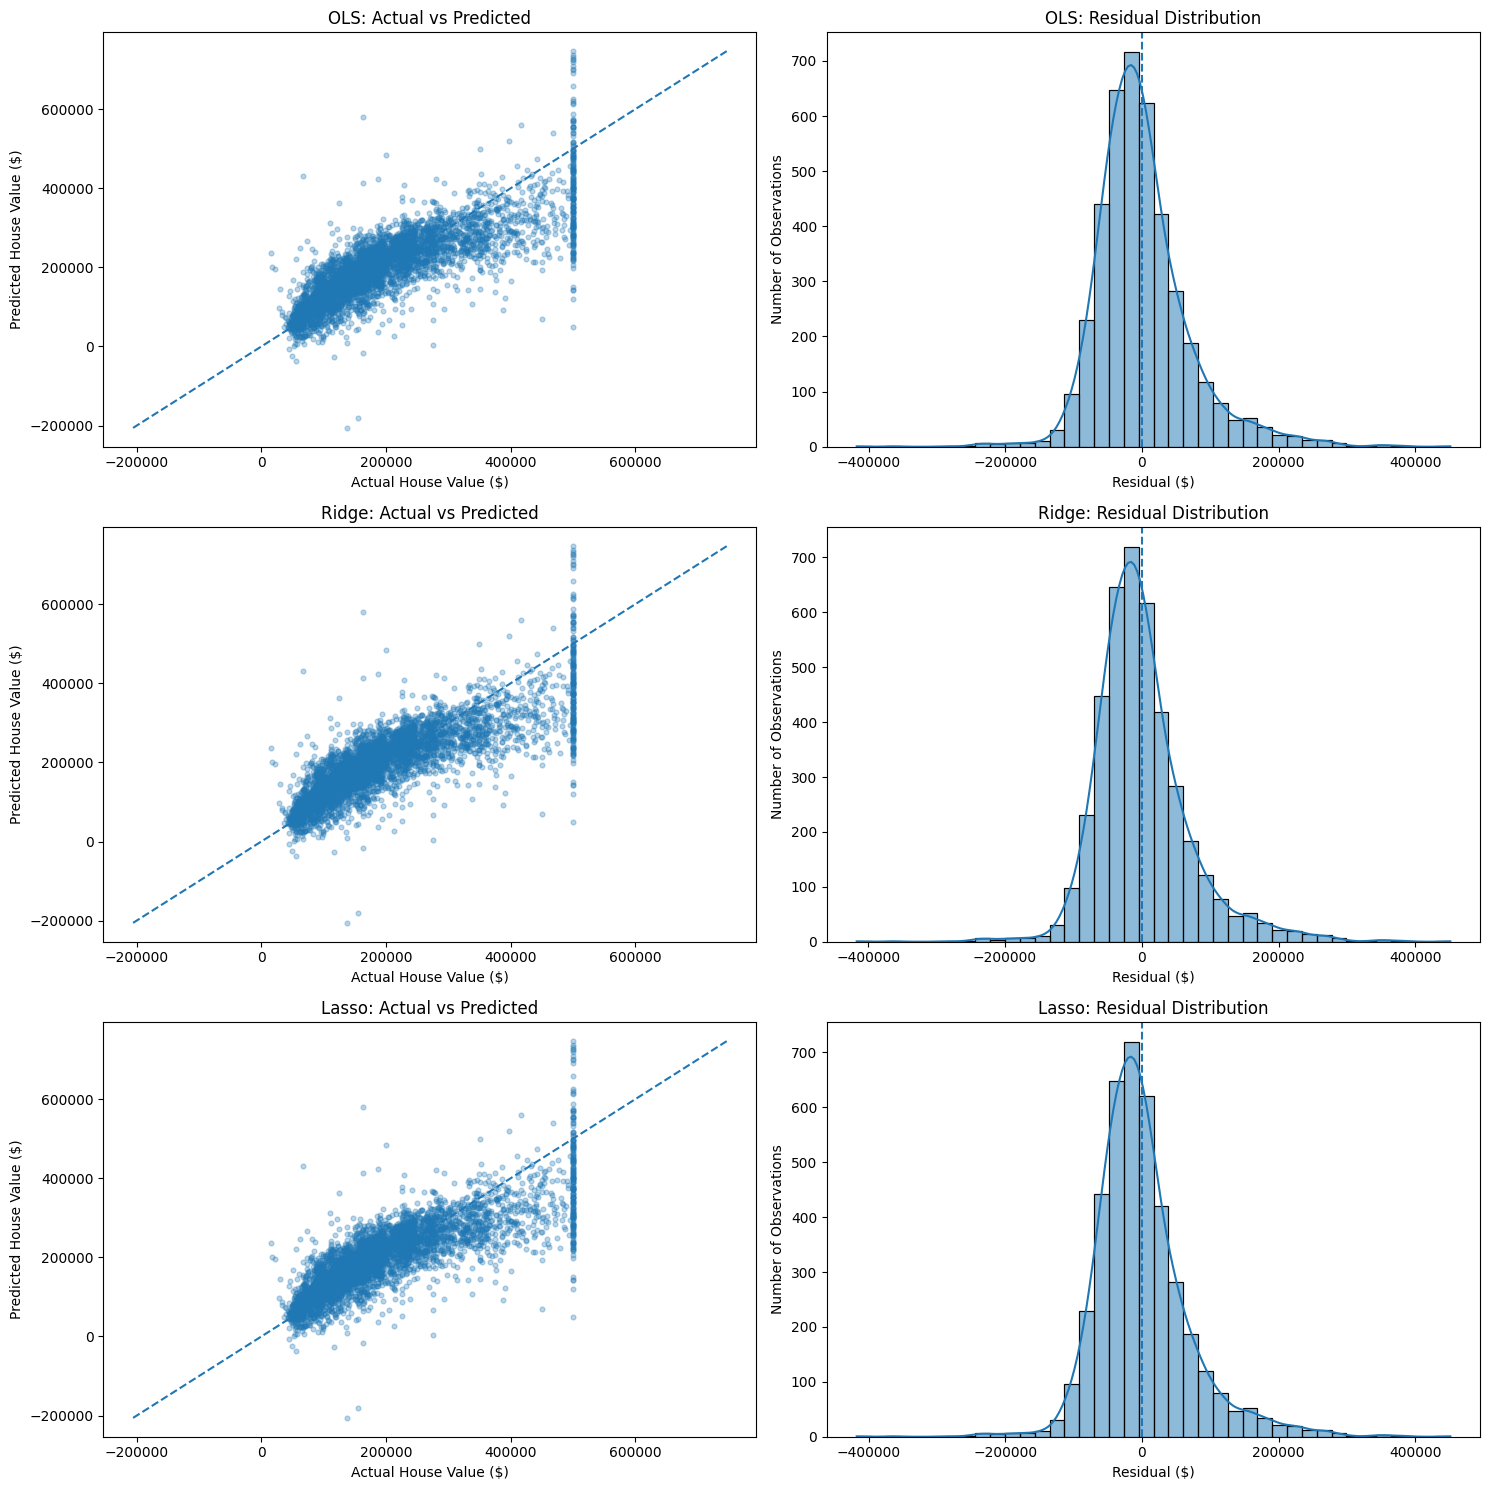

In [12]:
# Create comparison plots for all three regression models
fig, axes = plt.subplots(3, 2, figsize=(15, 15))

for row, model_name in enumerate(models):
    y_pred = predictions[model_name]
    residuals = y_test.to_numpy() - y_pred

    # Actual versus predicted values
    axes[row, 0].scatter(y_test, y_pred, alpha=0.3, s=12)

    plot_min = min(y_test.min(), y_pred.min())
    plot_max = max(y_test.max(), y_pred.max())

    axes[row, 0].plot(
        [plot_min, plot_max],
        [plot_min, plot_max],
        linestyle="--"
    )

    axes[row, 0].set_title(f"{model_name}: Actual vs Predicted")
    axes[row, 0].set_xlabel("Actual House Value ($)")
    axes[row, 0].set_ylabel("Predicted House Value ($)")

    # Residual distribution
    sns.histplot(
        residuals,
        bins=40,
        kde=True,
        ax=axes[row, 1]
    )

    axes[row, 1].axvline(0, linestyle="--")
    axes[row, 1].set_title(f"{model_name}: Residual Distribution")
    axes[row, 1].set_xlabel("Residual ($)")
    axes[row, 1].set_ylabel("Number of Observations")

plt.tight_layout()
plt.show()

## 13. Conclusion

This project used the California Housing dataset to predict
median house values using OLS, Ridge, and Lasso regression.

The dataset was explored, engineered features were created,
and a preprocessing pipeline was configured to handle missing
values, scale numerical variables, and encode categorical data.
Correlation and VIF analysis were used to investigate
relationships between the input features.

Ridge and Lasso were tuned using five-fold GridSearchCV.
On the held-out test set, all three models achieved an R²
of approximately 0.636 and showed very similar performance.

OLS achieved the lowest test RMSE of approximately $69,048
and MAE of approximately $49,376. Its advantage over Ridge
and Lasso was small, so the results do not indicate a
substantial performance difference between these models.

The actual-versus-predicted plots and residual distributions
were examined to understand prediction errors. The dataset's
upper house-value cap and occasional negative predictions
are important limitations to consider.

Overall, this project demonstrates regression modelling,
feature engineering, preprocessing, hyperparameter tuning,
evaluation, and residual analysis on housing data.